<center>
<img src="img/logo-hds.png" width="650"/>

***

<center>Lecture 3</center>

***

<center>Data wrangling, cohort auditing, annotation preparation and exploratory analysis</center>  

***

<center>21 September 2026<center>
<center>Rahman Peimankar<center>

## Today's lecture

Lecture 2 answered:

> **How do I access a PhysioNet/WFDB record?**

Today we answer:

> **I have many records and annotations. How do I turn them into a trustworthy analysis dataset?**

We will **not** repeat a tour of `rdheader()`, `rdrecord()`, `rdann()` and basic plotting.

Instead, we use those tools to build a realistic analysis workflow.

## Today's real-world question

Imagine you want to analyse ECG beats across several records.

Before modelling anything, you need to know:

- Are sampling frequencies consistent?
- Do records have the same channels and units?
- Which annotations actually occur?
- Are annotations distributed equally across records?
- Which events can safely become analysis windows?
- Which IDs must be preserved for future train/test splitting?
- What should be saved so the workflow is reproducible?

That is **exploratory data preparation**, not just file loading.

## Learning outcomes

By the end of today you should be able to:

1. build a **record-level manifest** for a small cohort;
2. audit sampling rates, durations, channels and units;
3. perform simple signal sanity checks without preprocessing;
4. combine annotations from multiple records into one tidy table;
5. inspect annotation distributions across records;
6. distinguish raw annotation labels from analysis labels;
7. create an **event index** for future segment extraction;
8. preserve provenance and grouping information for later modelling.

## Three analysis tables

Today we will create three reusable tables.

### 1. Record manifest
**one row = one record**

```text
record_id | fs | duration_s | channels | units | ...
```

### 2. Annotation table
**one row = one event**

```text
record_id | sample | time_s | symbol | ...
```

### 3. Event index
**one row = one future analysis segment**

```text
event_id | record_id | start_sample | end_sample | label | ...
```

These tables become the bridge to Lectures 4–9.

## Keep the hierarchy clear

Physiological datasets often have several levels:

```text
participant
   ↓
record / visit
   ↓
channel
   ↓
sample
   ↓
event / annotation
   ↓
analysis window
```

A major source of errors is losing the relationship between these levels.

### Rule

Never create a feature row without knowing **which participant/record/window it came from**.

## Setup

We use a small subset of the **MIT-BIH Arrhythmia Database** as a realistic cohort.

The objective is not ECG diagnosis.

The objective is to learn how to:

- audit several records;
- organize annotations;
- create analysis-ready metadata.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb

plt.rcParams["figure.figsize"] = (12, 4)

DATABASE = "mitdb"

# Small cohort for live coding.
# The same workflow scales to the complete record list later.
RECORDS = ["100", "101", "102", "103", "104", "105"]

print("Records:", RECORDS)

Records: ['100', '101', '102', '103', '104', '105']


## Step 1 — Build a record manifest

Do not begin a multi-record analysis by repeatedly opening arbitrary records.

First create a **manifest**.

For every record we want:

- record ID;
- sampling frequency;
- number of samples;
- duration;
- number of channels;
- channel names;
- units.

This immediately exposes dataset heterogeneity.

In [2]:
def build_record_manifest(database, record_ids):
    rows = []

    for record_id in record_ids:
        h = wfdb.rdheader(record_id, pn_dir=database)

        rows.append({
            "record_id": record_id,
            "fs_hz": float(h.fs),
            "sig_len": int(h.sig_len),
            "duration_s": h.sig_len / h.fs,
            "n_channels": int(h.n_sig),
            "channels": " | ".join(h.sig_name),
            "units": " | ".join(h.units),
        })

    return pd.DataFrame(rows)

manifest = build_record_manifest(DATABASE, RECORDS)
manifest

,record_id,fs_hz,sig_len,duration_s,n_channels,channels,units
0,100,360.0,650000,1805.555556,2,MLII | V5,mV | mV
1,101,360.0,650000,1805.555556,2,MLII | V1,mV | mV
2,102,360.0,650000,1805.555556,2,V5 | V2,mV | mV
3,103,360.0,650000,1805.555556,2,MLII | V2,mV | mV
4,104,360.0,650000,1805.555556,2,V5 | V2,mV | mV
5,105,360.0,650000,1805.555556,2,MLII | V1,mV | mV


## Inspect dataset consistency

A real dataset audit asks questions such as:

- Is `fs` the same for every record?
- Is the number of channels constant?
- Are the channel names identical?
- Are the units compatible?
- Do record durations vary?

These checks should happen **before** feature extraction.

In [3]:
audit_summary = pd.Series({
    "n_records": len(manifest),
    "sampling_rates": sorted(manifest["fs_hz"].unique().tolist()),
    "channel_counts": sorted(manifest["n_channels"].unique().tolist()),
    "unique_channel_patterns": manifest["channels"].nunique(),
    "unique_unit_patterns": manifest["units"].nunique(),
    "min_duration_min": manifest["duration_s"].min() / 60,
    "max_duration_min": manifest["duration_s"].max() / 60,
})

audit_summary

n_records                          6
sampling_rates               [360.0]
channel_counts                   [2]
unique_channel_patterns            4
unique_unit_patterns               1
min_duration_min           30.092593
max_duration_min           30.092593
dtype: object

## Channel names are data, not decoration

Two records may both contain two ECG channels but use different channel names.

For later pipelines, avoid assumptions such as:

```python
signal[:, 0]  # "this must always be MLII"
```

Instead preserve:

```text
record_id
channel_index
channel_name
unit
```

This becomes especially important when combining datasets.

In [4]:
manifest[
    ["record_id", "n_channels", "channels", "units"]
]

,record_id,n_channels,channels,units
0,100,2,MLII | V5,mV | mV
1,101,2,MLII | V1,mV | mV
2,102,2,V5 | V2,mV | mV
3,103,2,MLII | V2,mV | mV
4,104,2,V5 | V2,mV | mV
5,105,2,MLII | V1,mV | mV


## Automated checks: fail early

A robust analysis can include explicit checks.

Examples:

- expected sampling frequency;
- minimum number of channels;
- required unit;
- non-zero duration.

If an assumption fails, we want to know **before** running an hour-long pipeline.

In [5]:
EXPECTED_FS = 360

manifest["fs_ok"] = manifest["fs_hz"] == EXPECTED_FS
manifest["duration_ok"] = manifest["duration_s"] > 0
manifest["has_signal"] = manifest["n_channels"] >= 1

manifest[
    ["record_id", "fs_ok", "duration_ok", "has_signal"]
]

,record_id,fs_ok,duration_ok,has_signal
0,100,True,True,True
1,101,True,True,True
2,102,True,True,True
3,103,True,True,True
4,104,True,True,True
5,105,True,True,True


## Step 2 — Signal sanity checks

Before filtering in Lecture 4, we can still ask basic questions:

- Are there NaNs?
- Is the signal nearly flat?
- Is the amplitude range extremely unusual?
- Is there enough variability to contain a waveform?

These are **sanity checks**, not signal cleaning.

In [6]:
def signal_snapshot_metrics(
    database,
    record_id,
    duration_s=30,
    channel=0
):
    h = wfdb.rdheader(record_id, pn_dir=database)
    fs = int(h.fs)

    rec = wfdb.rdrecord(
        record_id,
        pn_dir=database,
        sampfrom=0,
        sampto=int(duration_s * fs),
        channels=[channel]
    )

    x = rec.p_signal[:, 0].astype(float)
    finite = np.isfinite(x)
    xf = x[finite]

    if len(xf) < 2:
        std = np.nan
        amplitude_range = np.nan
        flat_fraction = np.nan
    else:
        dx = np.diff(xf)
        std = np.std(xf)
        amplitude_range = np.ptp(xf)
        flat_fraction = np.mean(np.abs(dx) < 1e-6)

    return {
        "record_id": record_id,
        "channel_name": rec.sig_name[0],
        "unit": rec.units[0],
        "missing_fraction": 1 - finite.mean(),
        "std": std,
        "amplitude_range": amplitude_range,
        "flat_fraction": flat_fraction,
    }

## Audit a short snapshot from every record

We deliberately use only the first 30 seconds.

Why?

- fast;
- enough for basic sanity checks;
- avoids downloading entire recordings during exploration.

Later processing can scale to the full records.

In [7]:
snapshot_rows = [signal_snapshot_metrics(DATABASE,record_id,duration_s=30,channel=0) for record_id in RECORDS]

signal_audit = pd.DataFrame(snapshot_rows)
signal_audit

,record_id,channel_name,unit,missing_fraction,std,amplitude_range,flat_fraction
0,100,MLII,mV,0.0,0.173697,1.730,0.162978
1,101,MLII,mV,0.0,0.200209,1.965,0.150477
2,102,V5,mV,0.0,0.177425,1.695,0.151033
3,103,MLII,mV,0.0,0.317779,2.750,0.141124
4,104,V5,mV,0.0,0.289277,2.875,0.130382
5,105,MLII,mV,0.0,0.306116,2.570,0.135198


## Compare records visually with summary metrics

Plots help reveal records that deserve closer inspection.

Here we are **not** deciding whether a record is clinically good or bad.

We are asking:

> Which records look different enough that I should inspect them?

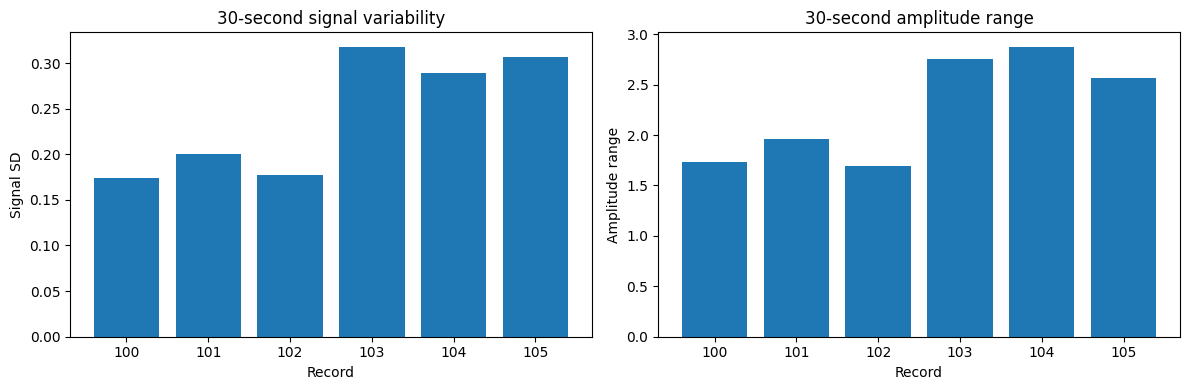

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(signal_audit["record_id"], signal_audit["std"])
axes[0].set_xlabel("Record")
axes[0].set_ylabel("Signal SD")
axes[0].set_title("30-second signal variability")

axes[1].bar(
    signal_audit["record_id"],
    signal_audit["amplitude_range"]
)
axes[1].set_xlabel("Record")
axes[1].set_ylabel("Amplitude range")
axes[1].set_title("30-second amplitude range")

plt.tight_layout()
plt.show()

## Important: do not clean yet

If a record looks unusual, the next action is:

1. inspect the waveform;
2. inspect metadata;
3. compare with another segment;
4. understand the cause.

It is **not** automatically:

```text
apply a filter
```

Lecture 4 will cover sampling, filtering and signal-quality decisions.

Today our goal is to preserve what we observe.

## Step 3 — Build one annotation table

Lecture 2 loaded annotations from one record.

Real analysis needs a table across **many records**.

We will preserve:

- record ID;
- annotation sample;
- annotation time;
- raw annotation symbol;
- auxiliary note.

The raw symbol should never be discarded when creating analysis labels.

In [9]:
def load_annotation_table(
    database,
    record_id,
    extension="atr"
):
    h = wfdb.rdheader(record_id, pn_dir=database)
    ann = wfdb.rdann(
        record_id,
        extension,
        pn_dir=database
    )

    return pd.DataFrame({
        "record_id": record_id,
        "sample": ann.sample.astype(int),
        "time_s": ann.sample / h.fs,
        "symbol": ann.symbol,
        "aux_note": ann.aux_note,
    })

annotation_tables = [
    load_annotation_table(DATABASE, r)
    for r in RECORDS
]

annotations = pd.concat(
    annotation_tables,
    ignore_index=True
)

annotations.head(10)

,record_id,sample,time_s,symbol,aux_note
0,100,18,0.050000,+,(N 
1,100,77,0.213889,N,
2,100,370,1.027778,N,
3,100,662,1.838889,N,
4,100,946,2.627778,N,
5,100,1231,3.419444,N,
6,100,1515,4.208333,N,
7,100,1809,5.025000,N,
8,100,2044,5.677778,A,
9,100,2402,6.672222,N,


## Annotation-table sanity checks

Before using annotations as labels:

- Is the table empty?
- Are sample positions non-negative?
- Are times monotonic within each record?
- Which symbols occur?
- Are auxiliary notes present?
- Are unexpected labels rare or concentrated in one record?

Treat annotation metadata like any other dataset.

In [10]:
annotation_checks = pd.Series({
    "n_annotations": len(annotations),
    "n_records": annotations["record_id"].nunique(),
    "n_symbols": annotations["symbol"].nunique(),
    "min_sample": annotations["sample"].min(),
    "missing_symbols": annotations["symbol"].isna().sum(),
    "nonempty_aux_notes": (
        annotations["aux_note"]
        .fillna("")
        .astype(str)
        .str.strip()
        .ne("")
        .sum()
    ),
})

annotation_checks

n_annotations         13433
n_records                 6
n_symbols                 9
min_sample                7
missing_symbols           0
nonempty_aux_notes       54
dtype: int64

## Which annotation symbols actually occur?

Do not begin with a label mapping copied from a paper.

First inspect **your data**.

In [11]:
symbol_counts = (
    annotations["symbol"]
    .value_counts()
    .rename_axis("symbol")
    .reset_index(name="count")
)

symbol_counts.head(15)

,symbol,count
0,N,8969
1,/,3408
2,f,722
3,~,135
4,+,54
5,V,48
6,A,38
7,|,34
8,Q,25


## Class imbalance is visible before modelling

Plot annotation counts on a logarithmic scale.

Why log scale?

A few common symbols can otherwise hide rare events.

This is already useful information for:

- choosing a project target;
- deciding whether rare classes are feasible;
- later evaluation design.

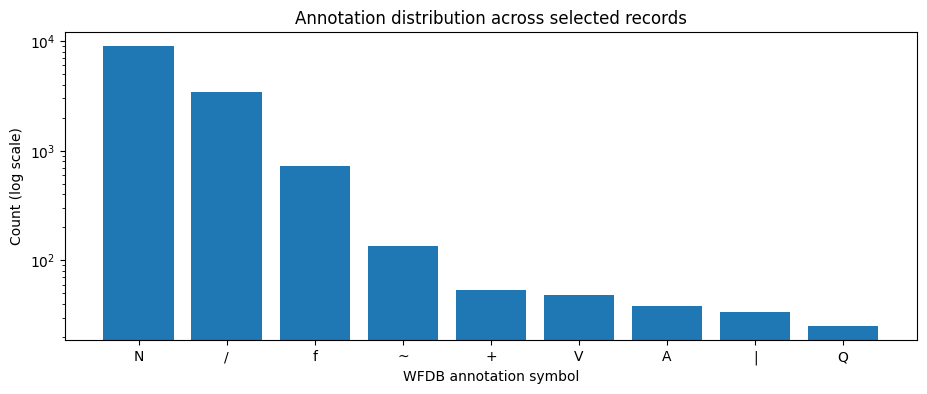

In [12]:
plot_counts = symbol_counts.head(15)

plt.figure(figsize=(11, 4))
plt.bar(plot_counts["symbol"], plot_counts["count"])
plt.yscale("log")
plt.xlabel("WFDB annotation symbol")
plt.ylabel("Count (log scale)")
plt.title("Annotation distribution across selected records")
plt.show()

## Distribution by record matters too

An event may be common overall but appear in only one record.

That matters later because:

> a classifier can accidentally learn **record identity** instead of the intended physiology.

So we inspect both:

- total class count;
- class count **per record**.

In [13]:
per_record_symbols = pd.crosstab(
    annotations["record_id"],
    annotations["symbol"]
)

# Show the most common symbols only
top_symbols = symbol_counts["symbol"].head(10).tolist()

per_record_symbols[top_symbols]

symbol,N,/,f,~,+,V,A,|,Q
record_id,,,,,,,,,
100,2239,0,0,0,1,1,33,0,0
101,1860,0,0,4,1,0,3,4,2
102,99,2028,56,0,5,4,0,0,0
103,2082,0,0,6,1,0,2,0,0
104,163,1380,666,37,45,2,0,0,18
105,2526,0,0,88,1,41,0,30,5


## Visualize annotation heterogeneity

A simple matrix can reveal:

- symbols concentrated in individual records;
- records with very different event composition;
- rare classes;
- potential future split problems.

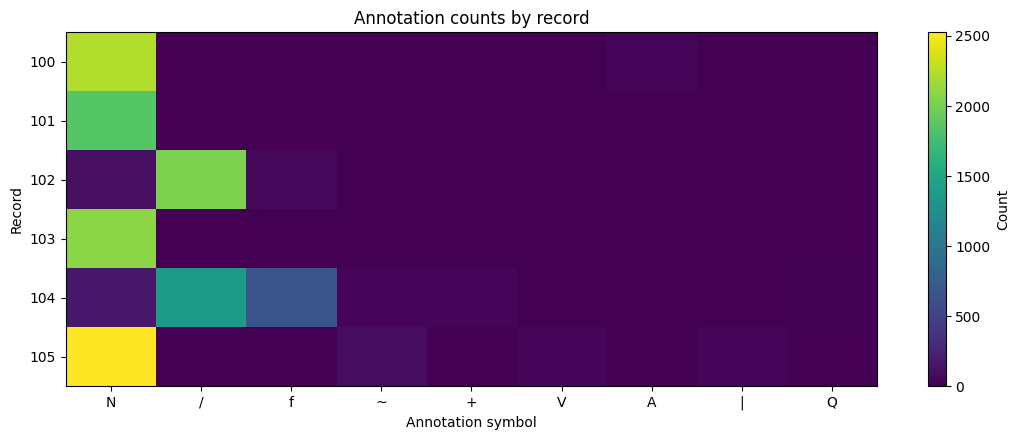

In [14]:
matrix = per_record_symbols[top_symbols].to_numpy()

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(matrix, aspect="auto")

ax.set_xticks(np.arange(len(top_symbols)))
ax.set_xticklabels(top_symbols)

ax.set_yticks(np.arange(len(per_record_symbols.index)))
ax.set_yticklabels(per_record_symbols.index)

ax.set_xlabel("Annotation symbol")
ax.set_ylabel("Record")
ax.set_title("Annotation counts by record")

plt.colorbar(im, ax=ax, label="Count")
plt.tight_layout()
plt.show()

## Annotation symbols need a dictionary

A raw symbol such as:

```text
N
V
A
+
~
```

is not self-explanatory.

Use the WFDB annotation-label table and the dataset documentation.

### Important

Not every annotation is necessarily a **beat class**.

Some symbols can describe rhythm changes, waveform quality or other events.

In [4]:
annotation_dictionary = wfdb.show_ann_labels()

if isinstance(annotation_dictionary, pd.DataFrame):
    display(annotation_dictionary.head(20))


    label_store symbol                                    description
0             0                              Not an actual annotation
1             1      N                                    Normal beat
2             2      L                  Left bundle branch block beat
3             3      R                 Right bundle branch block beat
4             4      a                Aberrated atrial premature beat
5             5      V              Premature ventricular contraction
6             6      F          Fusion of ventricular and normal beat
7             7      J              Nodal (junctional) premature beat
8             8      A                   Atrial premature contraction
9             9      S     Premature or ectopic supraventricular beat
10           10      E                        Ventricular escape beat
11           11      j                 Nodal (junctional) escape beat
12           12      /                                     Paced beat
13           13     

## Raw labels vs analysis labels

A good analysis table keeps both.

For example:

| raw symbol | analysis group |
|---|---|
| `N` | N |
| `V` | V |
| `A` | A |
| anything else | OTHER |

This is only an **example analysis mapping**.

The mapping for a real study must come from:

- the scientific question;
- dataset documentation;
- the paper you are reproducing.

Never overwrite the original symbol.

In [16]:
TARGET_MAP = {
    "N": "N",
    "V": "V",
    "A": "A",
}

annotations["analysis_label"] = (
    annotations["symbol"]
    .map(TARGET_MAP)
    .fillna("OTHER")
)

annotations[
    ["record_id", "sample", "time_s", "symbol", "analysis_label"]
].head(12)

,record_id,sample,time_s,symbol,analysis_label
0,100,18,0.050000,+,OTHER
1,100,77,0.213889,N,N
2,100,370,1.027778,N,N
3,100,662,1.838889,N,N
4,100,946,2.627778,N,N
5,100,1231,3.419444,N,N
6,100,1515,4.208333,N,N
7,100,1809,5.025000,N,N
8,100,2044,5.677778,A,A
9,100,2402,6.672222,N,N


## Inspect the mapped target before using it

After mapping labels, immediately inspect:

- total counts;
- counts by record;
- proportion of `OTHER`.

A mapping that produces only a handful of positive examples may not support the intended analysis.

In [17]:
mapped_counts = (
    annotations["analysis_label"]
    .value_counts()
    .rename_axis("analysis_label")
    .reset_index(name="count")
)

mapped_counts

,analysis_label,count
0,N,8969
1,OTHER,4378
2,V,48
3,A,38


## Step 4 — Verify signal/annotation alignment

Before creating thousands of segments, inspect a few examples.

For one event:

1. obtain its record and sample index;
2. load a short region around the event;
3. plot the signal;
4. mark the annotation.

This catches:

- wrong record IDs;
- wrong sampling assumptions;
- indexing mistakes;
- incorrect annotation offsets.

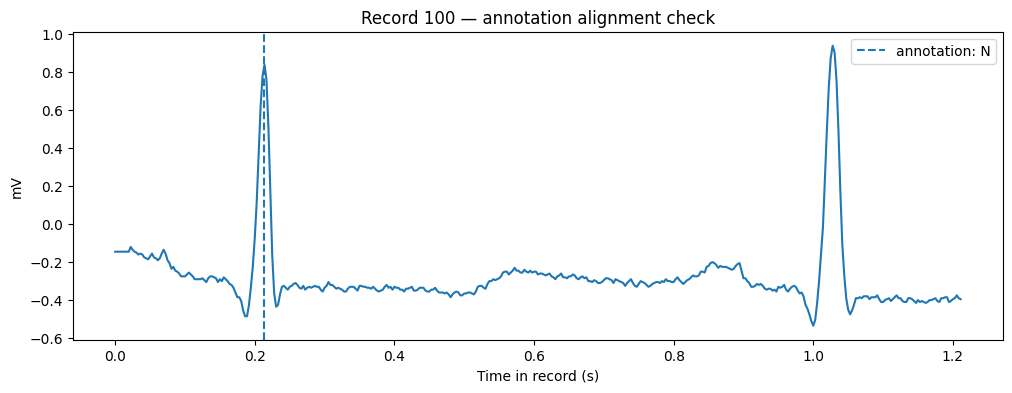

In [18]:
example = annotations[
    annotations["symbol"].isin(["N", "V", "A"])
].iloc[0]

record_id = example["record_id"]
event_sample = int(example["sample"])

h = wfdb.rdheader(record_id, pn_dir=DATABASE)
fs_event = int(h.fs)

pre_s = 1.0
post_s = 1.0

start_sample = max(
    0,
    event_sample - int(pre_s * fs_event)
)

end_sample = min(
    h.sig_len,
    event_sample + int(post_s * fs_event)
)

event_record = wfdb.rdrecord(
    record_id,
    pn_dir=DATABASE,
    sampfrom=start_sample,
    sampto=end_sample,
    channels=[0]
)

x_event = event_record.p_signal[:, 0]
t_event = (
    np.arange(len(x_event)) + start_sample
) / fs_event

plt.plot(t_event, x_event)
plt.axvline(
    event_sample / fs_event,
    linestyle="--",
    label=f"annotation: {example['symbol']}"
)

plt.xlabel("Time in record (s)")
plt.ylabel(event_record.units[0])
plt.title(f"Record {record_id} — annotation alignment check")
plt.legend()
plt.show()

## Do not store thousands of signal arrays in one DataFrame

A common beginner approach is:

```text
DataFrame cell = entire ECG window
```

That becomes difficult to inspect, save and reproduce.

A more scalable approach is to create an **event/window index**:

```text
event_id
record_id
event_sample
start_sample
end_sample
channel
label
```

Load the waveform only when needed.

## Step 5 — Build an event index

Suppose a future analysis wants a window:

- 0.4 s before each selected annotation;
- 0.6 s after it.

Today we only create the **index**.

Lecture 4 will discuss segmentation choices in more depth.

In [19]:
def make_event_index(
    annotations,
    manifest,
    pre_s=0.4,
    post_s=0.6,
    allowed_symbols=("N", "V", "A")
):
    fs_map = manifest.set_index("record_id")["fs_hz"].to_dict()
    len_map = manifest.set_index("record_id")["sig_len"].to_dict()

    rows = []

    selected = annotations[
        annotations["symbol"].isin(allowed_symbols)
    ].copy()

    for _, row in selected.iterrows():
        record_id = row["record_id"]
        fs = fs_map[record_id]
        sig_len = len_map[record_id]

        event_sample = int(row["sample"])
        start_sample = event_sample - int(pre_s * fs)
        end_sample = event_sample + int(post_s * fs)

        valid = (
            start_sample >= 0
            and end_sample <= sig_len
        )

        rows.append({
            "event_id": f"{record_id}_{event_sample}",
            "record_id": record_id,
            "event_sample": event_sample,
            "event_time_s": row["time_s"],
            "raw_symbol": row["symbol"],
            "analysis_label": row["analysis_label"],
            "start_sample": start_sample,
            "end_sample": end_sample,
            "channel_index": 0,
            "valid_window": valid,
        })

    return pd.DataFrame(rows)

event_index = make_event_index(
    annotations,
    manifest
)

event_index.head()

,event_id,record_id,event_sample,event_time_s,raw_symbol,analysis_label,start_sample,end_sample,channel_index,valid_window
0,100_77,100,77,0.213889,N,N,-67,293,0,False
1,100_370,100,370,1.027778,N,N,226,586,0,True
2,100_662,100,662,1.838889,N,N,518,878,0,True
3,100_946,100,946,2.627778,N,N,802,1162,0,True
4,100_1231,100,1231,3.419444,N,N,1087,1447,0,True


## Boundary checks are essential

Events close to the beginning or end of a recording may not have enough context.

Instead of silently producing shorter windows, we flag them:

```text
valid_window = True / False
```

This makes exclusion transparent and reproducible.

In [20]:
event_index["valid_window"].value_counts()

valid_window
True     9051
False       4
Name: count, dtype: int64

## Preserve grouping information now

For later modelling we need a grouping variable.

At minimum preserve:

```text
record_id
```

If the dataset provides a true participant ID, preserve that too.

### Important

`record_id` and `participant_id` are **not automatically the same thing**.

Later, Lecture 9 will use grouping information to avoid train/test leakage.

In [21]:
event_index["group_id"] = event_index["record_id"]

event_index[
    [
        "event_id",
        "record_id",
        "group_id",
        "analysis_label",
        "start_sample",
        "end_sample",
        "valid_window",
    ]
].head()

,event_id,record_id,group_id,analysis_label,start_sample,end_sample,valid_window
0,100_77,100,100,N,-67,293,False
1,100_370,100,100,N,226,586,True
2,100_662,100,100,N,518,878,True
3,100_946,100,100,N,802,1162,True
4,100_1231,100,100,N,1087,1447,True


## Class balance after window preparation

The relevant class distribution is not always the raw annotation distribution.

After:

- selecting symbols;
- applying boundary checks;
- choosing records;

the usable class counts can change.

Always inspect the **final candidate dataset**.

In [22]:
usable_events = event_index[
    event_index["valid_window"]
].copy()

usable_counts = pd.crosstab(
    usable_events["record_id"],
    usable_events["analysis_label"]
)

usable_counts

analysis_label,A,N,V
record_id,,,
100,33,2237,1
101,3,1859,0
102,0,99,4
103,2,2081,0
104,0,163,2
105,0,2526,41


## Load an indexed waveform only when needed

The index tells us exactly where the segment lives.

This is much easier to scale than storing arrays in a CSV.

In [23]:
def load_indexed_event(
    row,
    database="mitdb"
):
    rec = wfdb.rdrecord(
        row["record_id"],
        pn_dir=database,
        sampfrom=int(row["start_sample"]),
        sampto=int(row["end_sample"]),
        channels=[int(row["channel_index"])]
    )

    return rec.p_signal[:, 0], rec.fs, rec.sig_name[0], rec.units[0]


example_row = usable_events.iloc[0]
segment, segment_fs, channel_name, unit = load_indexed_event(
    example_row,
    DATABASE
)

print("Event:", example_row["event_id"])
print("Label:", example_row["analysis_label"])
print("Segment shape:", segment.shape)
print("Sampling frequency:", segment_fs)
print("Channel:", channel_name)
print("Unit:", unit)

Event: 100_370
Label: N
Segment shape: (360,)
Sampling frequency: 360
Channel: MLII
Unit: mV


## Plot several indexed examples

A real-world pipeline should include spot checks from:

- different records;
- different labels;
- different parts of recordings.

This helps detect systematic indexing or labelling errors before preprocessing.

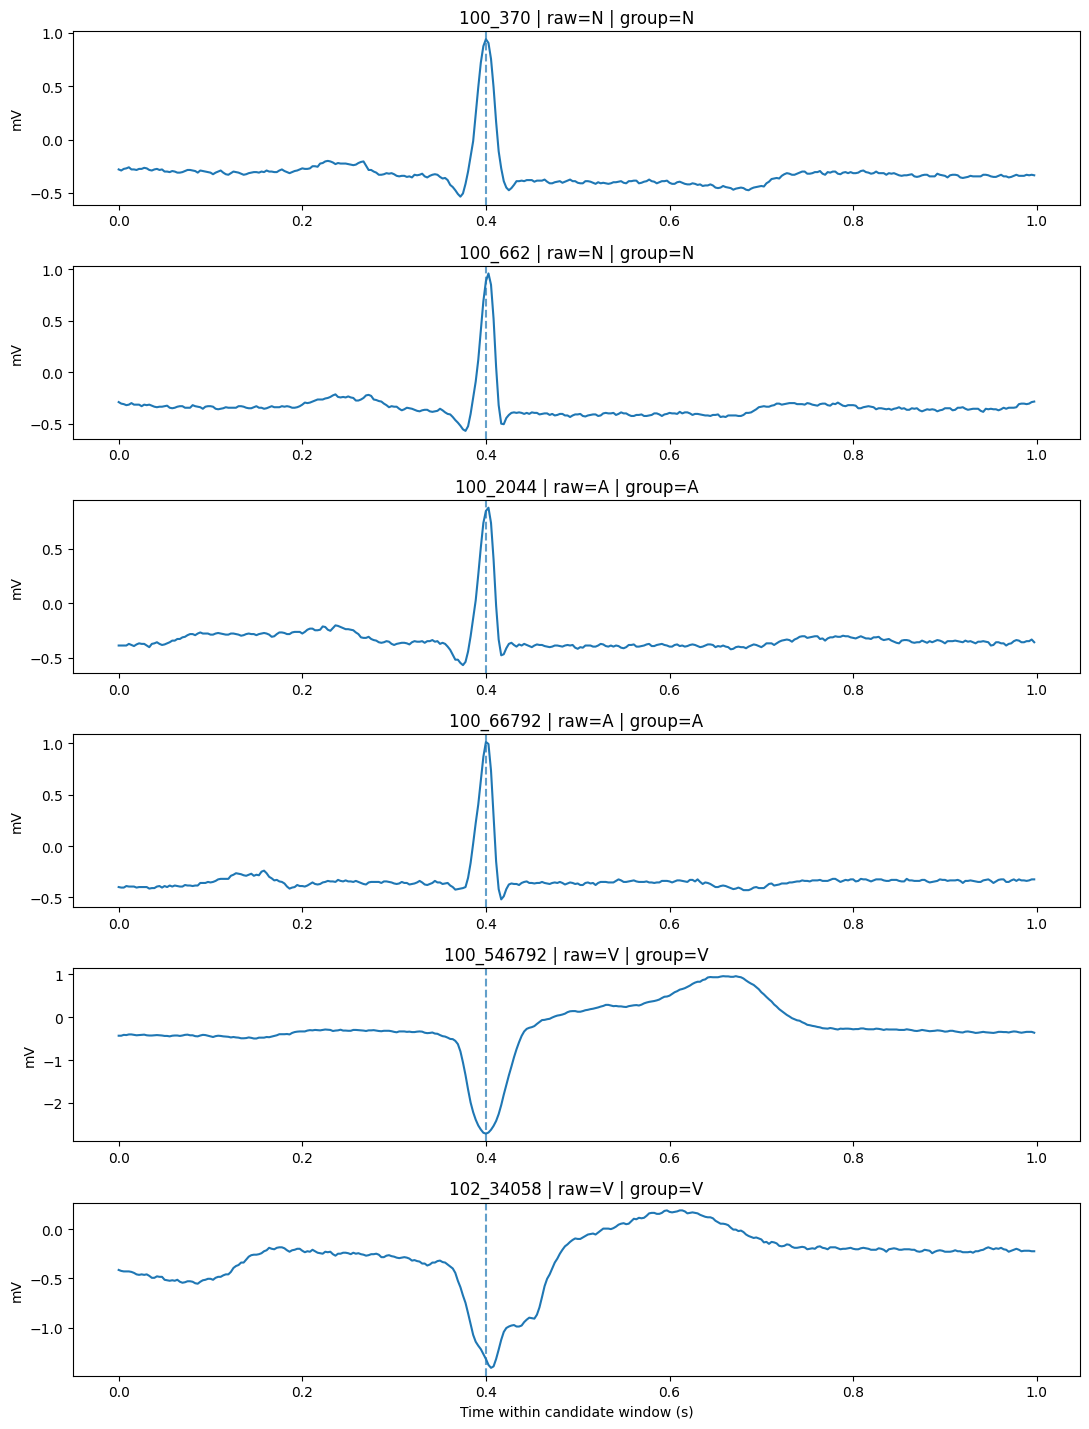

In [24]:
examples = (
    usable_events
    .groupby("analysis_label", group_keys=False)
    .head(2)
    .head(6)
)

fig, axes = plt.subplots(
    len(examples),
    1,
    figsize=(11, 2.4 * len(examples))
)

if len(examples) == 1:
    axes = [axes]

for ax, (_, row) in zip(axes, examples.iterrows()):
    x, fs_seg, ch, unit_seg = load_indexed_event(row, DATABASE)
    tt = np.arange(len(x)) / fs_seg

    ax.plot(tt, x)
    ax.axvline(0.4, linestyle="--", alpha=0.7)
    ax.set_title(
        f"{row['event_id']} | raw={row['raw_symbol']} | "
        f"group={row['analysis_label']}"
    )
    ax.set_ylabel(unit_seg)

axes[-1].set_xlabel("Time within candidate window (s)")
plt.tight_layout()
plt.show()

## What should we save?

After exploratory preparation, save **small reproducible tables**, not duplicated raw waveforms.

Suggested outputs:

```text
processed/
    record_manifest.csv
    signal_audit.csv
    annotations_long.csv
    event_index.csv
```

Raw PhysioNet data can still be loaded from the documented source.

This separates:

- source data;
- derived metadata;
- later features/models.

In [25]:
# Example only — uncomment in your project after creating folders.

# manifest.to_csv("processed/record_manifest.csv", index=False)
# signal_audit.to_csv("processed/signal_audit.csv", index=False)
# annotations.to_csv("processed/annotations_long.csv", index=False)
# event_index.to_csv("processed/event_index.csv", index=False)

## A reproducibility checklist

Before moving to preprocessing, ask:

### Records
- Do I know which records are included?
- Are channels, units and sampling rates documented?

### Signals
- Have I checked for missing/flat/unusual segments?

### Annotations
- Do I know what each raw label means?
- Did I preserve the original label?

### Analysis units
- Can every future window be traced back to its record?
- Do I have a grouping variable for later splitting?

If yes, the dataset is ready for the next stage.

## Exercise 1 — Build an analysis-ready cohort audit

### 30 minutes

Use records:

```text
100, 101, 103, 105
```

### Tasks

1. create a record manifest;
2. audit the first 30 s of channel 0;
3. create one combined annotation table;
4. show annotation counts overall and by record;
5. map `N`, `V`, and `A` to analysis labels and everything else to `OTHER`;
6. identify one record/label combination that deserves closer inspection;
7. write three observations.

### Starter code

In [26]:
EX_RECORDS = ["100", "101", "103", "105"]

# 1. Record manifest
exercise_manifest = build_record_manifest(
    DATABASE,
    EX_RECORDS
)

exercise_manifest

,record_id,fs_hz,sig_len,duration_s,n_channels,channels,units
0,100,360.0,650000,1805.555556,2,MLII | V5,mV | mV
1,101,360.0,650000,1805.555556,2,MLII | V1,mV | mV
2,103,360.0,650000,1805.555556,2,MLII | V2,mV | mV
3,105,360.0,650000,1805.555556,2,MLII | V1,mV | mV


In [27]:
# 2. Signal audit

exercise_signal_audit = pd.DataFrame([
    signal_snapshot_metrics(
        DATABASE,
        r,
        duration_s=30,
        channel=0
    )
    for r in EX_RECORDS
])

exercise_signal_audit

,record_id,channel_name,unit,missing_fraction,std,amplitude_range,flat_fraction
0,100,MLII,mV,0.0,0.173697,1.730,0.162978
1,101,MLII,mV,0.0,0.200209,1.965,0.150477
2,103,MLII,mV,0.0,0.317779,2.750,0.141124
3,105,MLII,mV,0.0,0.306116,2.570,0.135198


In [28]:
# 3. Combined annotation table

exercise_annotations = pd.concat(
    [
        load_annotation_table(DATABASE, r)
        for r in EX_RECORDS
    ],
    ignore_index=True
)

# TODO:
# Show overall symbol counts.

# TODO:
# Create a record × symbol table.

In [29]:
# 4. Analysis-label mapping

TARGET_MAP_EX = {
    "N": "N",
    "V": "V",
    "A": "A",
}

# TODO:
# Add exercise_annotations["analysis_label"].

# TODO:
# Show counts overall and per record.

### Exercise 1 — interpretation

Write three observations:

1. What differs between the records?
2. Which annotation labels are strongly imbalanced or concentrated?
3. What would you inspect manually before using these data for modelling?

## Exercise 2 — Create a reusable event index

### 30 minutes

Continue from Exercise 1.

Create an index for future event-centred analysis using:

- symbols `N`, `V`, `A`;
- 0.4 s before each event;
- 0.6 s after each event;
- channel 0.

### Tasks

1. create the event index;
2. remove/flag invalid boundary windows;
3. add `group_id = record_id`;
4. inspect final class counts;
5. load and plot at least one indexed example from two labels;
6. decide what should be committed to your project repository.

### Starter code

In [1]:
# TODO 1:
# Build an event index from:
# exercise_annotations
# exercise_manifest

exercise_event_index = make_event_index(
    exercise_annotations,
    exercise_manifest,
    pre_s=0.4,
    post_s=0.6,
    allowed_symbols=("N", "V", "A")
)

# TODO 2:
# Add group_id.

# TODO 3:
# Keep valid windows only.

exercise_event_index.head()

In [ ]:
# TODO 4:
# Create a record × analysis_label count table.

# TODO 5:
# Select one example from at least two labels.

# TODO 6:
# Load the indexed waveforms with load_indexed_event(...)
# and plot them.

### Exercise 2 — project connection

For your semester-project dataset, write down:

- **record identifier:**  
- **participant identifier (if available):**  
- **signal/channel(s):**  
- **annotation/target source:**  
- **one row in your future analysis table will represent:**  
- **grouping variable for later train/test split:**  
- **derived tables you should save:**  

**Suggested commit**

```text
Add cohort and annotation preparation
```

## What we deliberately did NOT do today

We did not:

- design filters;
- resample signals;
- choose final window lengths for a model;
- extract HRV;
- calculate hundreds of features;
- train a classifier.

Those steps are much safer **after** the cohort, annotations and provenance have been audited.

### Next lecture

**Signal Quality + Sampling + Filtering + Segmentation + Preprocessing**

## Take-home message

A real biosignal project does not go directly from:

```text
WFDB → model
```

A safer workflow is:

```text
WFDB
  ↓
record manifest
  ↓
signal sanity audit
  ↓
annotation audit
  ↓
transparent label mapping
  ↓
analysis/event index
  ↓
preprocessing
  ↓
features
  ↓
modelling
```

**Good modelling begins with trustworthy data organization.**

## Sources and further reading

- [MIT-BIH Arrhythmia Database, version 1.0.0](https://www.physionet.org/content/mitdb/1.0.0/): dataset and citation.
- [MIT-BIH database directory](https://physionet.org/physiobank/database/html/mitdbdir/intro.htm): recording and annotation context.
- [WFDB Python I/O documentation](https://wfdb.readthedocs.io/en/latest/io.html): headers, signal reads and annotation descriptions.

Moody GB, Mark RG. *The impact of the MIT-BIH Arrhythmia Database.* IEEE Engineering in Medicine and Biology, 20(3), 45–50 (2001).
